# 多元線性迴歸圖解：ML 慢慢學 EP03 的程式

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ntanh-ml/ml-manmanxue/blob/main/v04-multiple-linear-regression/notebook.ipynb)

這本 notebook 產生影片裡**每一張資料圖和每一個數字**。所有資料都是**模擬資料，非實廠數據**，不代表任何一座真實焚化廠。
This notebook generates every data chart and number in EP03 of the YouTube channel ML 慢慢學 (https://www.youtube.com/@ml-step-by-step). All data are **simulated** and do not describe any real plant.

問題（接續 EP02）：**只看感測器，能不能預測下一個小時的蒸汽量？**

| 段落 | 對應影片 |
|---|---|
| 1. 模擬一座焚化爐 14 天的感測器資料 | 第 2 段 |
| 2. 答案欄：接下來一小時的平均蒸汽流量 | 第 2、4 段 |
| 3. 多元線性迴歸（直接用公式解） | 第 2、3 段 |
| 4. 麻煩：數字大小差太多（梯度下降法走不動） | 第 5 段 |
| 5. 特徵標準化 | 第 6 段 |
| 6. 標準化之後，權重能比較了 | 第 7 段 |
| 7. 拿沒看過的日子來測 | 第 8 段 |
| 8. 匯出資料給影片使用 | — |

參考：Google Machine Learning Crash Course〈正規化〉(zh-TW)；Tang, J. et al. (2024). *Sustainability*, 16(5), 2042；Galton, F. (1886). Regression towards mediocrity in hereditary stature；《廢棄物焚化爐戴奧辛管制及排放標準》第 7 條。

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Ellipse

PAPER, INK, RED, BLUE, AMBER, TEAL = "#F6F1E7", "#3B2F2A", "#D8573C", "#4FA3D1", "#D79A2B", "#2A9D8F"
LABEL = "模擬資料，非實廠數據"

# Chinese font for the plots. Uses LXGW WenKai TC (OFL) if present; otherwise Noto Sans CJK.
# On Google Colab the Noto CJK font is installed automatically so the Chinese labels display correctly.
import subprocess, sys
FONT = Path("../../tools/fonts/LXGWWenKaiTC-Medium.ttf")
CJK = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if not FONT.exists() and not CJK.exists() and "google.colab" in sys.modules:
    print("正在安裝中文字型（約 30 秒）…")
    if subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"]).returncode != 0:
        subprocess.run(["apt-get", "-qq", "update"])
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"])
for f in (FONT, CJK):
    if f.exists():
        font_manager.fontManager.addfont(str(f))
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(f)).get_name()
        break
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "axes.unicode_minus": False})

def tag(ax):
    ax.text(0.99, 0.97, LABEL, transform=ax.transAxes, ha="right", va="top", fontsize=8, color=RED)

def lag(x, tau):
    # 一階延遲：輸出慢慢追上輸入，tau 越大越慢 (first-order lag)
    y = np.empty_like(x); y[0] = x[0]
    for i in range(1, len(x)):
        y[i] = y[i - 1] + (x[i] - y[i - 1]) / tau
    return y

## 1. 模擬一座焚化爐 14 天的感測器資料
每分鐘一筆，共 14 天。下面的數量級是**為了示意而假設的**，不是任何一座廠的數據：

| 量 | 怎麼模擬 | 單位 |
|---|---|---|
| 垃圾熱值（量不到，只用來產生資料） | AR(1)，平均 2050、標準差 150，限制在 1500–2500（同 EP02） | 大卡/公斤 |
| 進料量 | 操作員每 2–6 小時調一次設定值，實際進料慢慢跟上（時間常數 15 分鐘） | 公噸/小時 |
| 一次空氣流量 | 約每公斤垃圾 3 Nm³，跟著進料設定值走（反應較快，5 分鐘），再加上獨立的微調 | Nm³/小時 |
| 爐溫 | 跟著放熱量（進料 × 熱值）變，空氣多一點會稍微降溫；法規要求二次空氣後一小時平均 ≥ 850°C，模擬值都在這之上 | °C |
| 含氧量 | 放熱多會用掉較多氧，空氣多則氧變多；同一條法規要求排氣含氧量 ≥ 6%，模擬值都在 6–10% 之間 | % |
| 蒸汽流量 | 約 80% 的放熱變成蒸汽（每公噸蒸汽約需 670 千大卡，示意），反應較慢（10 分鐘） | 公噸/小時 |

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


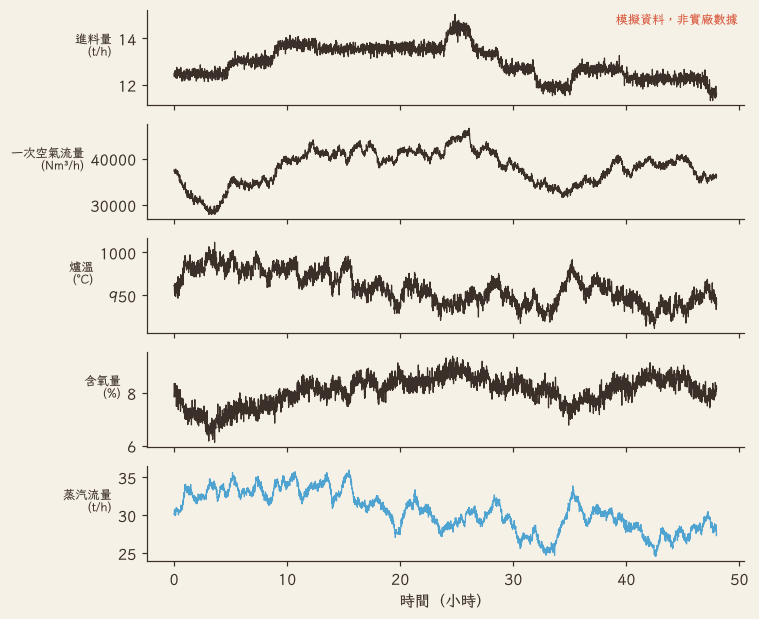

進料量：平均 12.7、最小 10.0、最大 15.0 t/h（模擬）
一次空氣流量：平均 37,941.8、最小 26,148.8、最大 47,861.6 Nm³/h（模擬）
爐溫：平均 962.1、最小 904.0、最大 1,032.6 °C（模擬）
含氧量：平均 8.0、最小 6.1、最大 9.6 %（模擬）
蒸汽流量：平均 31.0、最小 23.4、最大 41.8 t/h（模擬）


In [2]:
rng = np.random.default_rng(2026)
DAYS = 14
N = DAYS * 1440                      # minutes
t_min = np.arange(N)

# 垃圾熱值 (kcal/kg)：AR(1)，約 2 小時的相關時間
MU, SD = 2050.0, 150.0
PHI = np.exp(-1 / 120)
lhv = np.empty(N); lhv[0] = MU
noise = rng.normal(0, SD * np.sqrt(1 - PHI ** 2), N)
for i in range(1, N):
    lhv[i] = MU + PHI * (lhv[i - 1] - MU) + noise[i]
lhv = np.clip(lhv, 1500, 2500)

# 進料設定值 (t/h)：操作員每 2–6 小時調整一次
F_set = np.empty(N); i, level = 0, 12.5
while i < N:
    length = int(rng.integers(120, 360))
    level = float(np.clip(level + rng.normal(0, 0.7), 10.5, 14.5))
    F_set[i:i + length] = level; i += length
feed = lag(F_set, 15) + rng.normal(0, 0.15, N)

# 一次空氣流量 (Nm3/h)：約 3 Nm3/kg × 進料設定值，再加獨立微調
trim = np.empty(N); trim[0] = 0.0
PT = np.exp(-1 / 180)
e_trim = rng.normal(0, 0.06 * np.sqrt(1 - PT ** 2), N)
for i in range(1, N):
    trim[i] = PT * trim[i - 1] + e_trim[i]
air = lag(3000 * F_set * (1 + trim), 5) + rng.normal(0, 400, N)

Q0 = 12.5 * MU
q = feed * lhv / Q0                  # 放熱量（相對值，1 = 12.5 t/h × 2050 kcal/kg）
air_rel = air / (3000 * 12.5)
temp = 960 + 200 * (lag(q, 4) - 1) - 80 * (air_rel - 1) + rng.normal(0, 5, N)
o2 = 8.0 - 3.0 * (lag(q, 3) - 1) + 4.5 * (air_rel - 1) + rng.normal(0, 0.2, N)
steam = lag(feed * lhv * 0.8 / 670 - 4 * (air_rel - 1), 10) + rng.normal(0, 0.3, N)

NAMES = ["進料量", "一次空氣流量", "爐溫", "含氧量"]
UNITS = ["t/h", "Nm³/h", "°C", "%"]
raw = np.c_[feed, air, temp, o2]
assert temp.min() > 850 and 6 <= o2.min() and o2.max() < 10 and air.min() > 10000   # 法規：850°C、排氣含氧量 ≥ 6%

hours = t_min / 60
show = hours < 48
fig, axs = plt.subplots(5, 1, figsize=(7, 6.5), sharex=True)
for ax, s, name, unit in zip(axs, list(raw.T) + [steam], NAMES + ["蒸汽流量"], UNITS + ["t/h"]):
    ax.plot(hours[show], s[show], lw=0.8, color=BLUE if name == "蒸汽流量" else INK)
    ax.set_ylabel(f"{name}\n({unit})", rotation=0, ha="right", fontsize=8)
axs[-1].set_xlabel("時間（小時）"); tag(axs[0]); plt.show()
for name, unit, s in zip(NAMES + ["蒸汽流量"], UNITS + ["t/h"], list(raw.T) + [steam]):
    print(f"{name}：平均 {s.mean():,.1f}、最小 {s.min():,.1f}、最大 {s.max():,.1f} {unit}（模擬）")

## 2. 答案欄：接下來一小時的平均蒸汽流量
每一列（每一分鐘）的答案 = **接下來 60 分鐘**蒸汽流量的平均。輸入只用**那一分鐘已經量到的** 4 個感測器，不偷看未來。

In [3]:
H = 60
cs = np.cumsum(np.r_[0.0, steam])
rows = np.arange(N - H)
y = (cs[rows + 1 + H] - cs[rows + 1]) / H          # mean of steam[t+1 .. t+60]
X = raw[rows]
k = 5000
assert np.isclose(y[k], steam[k + 1:k + 1 + H].mean())

# 影片第 2 段的表格：每 4 小時取一列
table_rows = [int(r) for r in range(9 * 60, 9 * 60 + 6 * 240, 240)]
print("時間         進料量  一次空氣流量   爐溫  含氧量 | 接下來一小時的平均蒸汽流量")
for r in table_rows:
    d, m = divmod(r, 1440)
    print(f"第{d + 1}天 {m // 60:02d}:{m % 60:02d}  {X[r, 0]:5.1f}  {X[r, 1]:9,.0f}  {X[r, 2]:5.0f}  {X[r, 3]:5.1f}  | {y[r]:5.1f}")

時間         進料量  一次空氣流量   爐溫  含氧量 | 接下來一小時的平均蒸汽流量
第1天 09:00   13.5     36,022    984    7.4  |  34.1
第1天 13:00   13.6     41,739    979    8.2  |  34.1
第1天 17:00   13.5     42,989    951    8.8  |  31.5
第1天 21:00   13.8     41,989    946    8.5  |  31.3
第2天 01:00   14.1     44,313    935    8.8  |  29.5
第2天 05:00   12.8     38,450    946    8.3  |  29.3


## 3. 多元線性迴歸（直接用公式解）
$\hat y = w_1 x_1 + w_2 x_2 + w_3 x_3 + w_4 x_4 + b$。
用前 10 天訓練、後 4 天測試。訓練資料的最後 60 分鐘不用，因為它們的答案會用到測試期的蒸汽量。
線性迴歸有公式可以直接算出讓均方誤差最小的權重（最小平方法，`np.linalg.lstsq`）。

In [4]:
TRAIN_DAYS, TEST_DAYS = 10, 4
n_split = TRAIN_DAYS * 1440
tr = np.arange(0, n_split - H)                 # 訓練列
te = np.arange(n_split, len(y))                # 測試列

def with_bias(A):
    return np.c_[np.ones(len(A)), A]

coef_raw, *_ = np.linalg.lstsq(with_bias(X[tr]), y[tr], rcond=None)
pred_raw = with_bias(X) @ coef_raw

def mae(a, b): return float(np.abs(a - b).mean())
def r2(yt, yp): return float(1 - ((yt - yp) ** 2).sum() / ((yt - yt.mean()) ** 2).sum())

print("b =", round(coef_raw[0], 3))
for name, unit, w in zip(NAMES, UNITS, coef_raw[1:]):
    print(f"w({name}) = {w:.6g}  （{unit} 多 1，蒸汽多 {w:.6g} t/h）")
print(f"訓練 R² = {r2(y[tr], pred_raw[tr]):.2f}；測試 R² = {r2(y[te], pred_raw[te]):.2f}，平均絕對誤差 {mae(y[te], pred_raw[te]):.2f} t/h")

b = -75.135
w(進料量) = 0.510973  （t/h 多 1，蒸汽多 0.510973 t/h）
w(一次空氣流量) = 0.000214078  （Nm³/h 多 1，蒸汽多 0.000214078 t/h）
w(爐溫) = 0.102919  （°C 多 1，蒸汽多 0.102919 t/h）
w(含氧量) = -0.935525  （% 多 1，蒸汽多 -0.935525 t/h）
訓練 R² = 0.85；測試 R² = 0.83，平均絕對誤差 0.80 t/h


## 4. 麻煩：數字大小差太多
4 個感測器的數字大小差了好幾個數量級。用梯度下降法找權重時，損失的「碗」會被壓成又長又窄的山谷。

為了畫在平面上，先只看**兩個權重**：爐溫和含氧量（資料先減去平均，讓 b 不影響畫面）。
均方誤差是權重的二次函數，等高線是橢圓。兩種情況都用**各自最好的固定學習率** $2/(\lambda_{max}+\lambda_{min})$（沒標準化時，它幾乎就是發散邊界 $2/\lambda_{max}$，再大就發散），從權重 = 0 出發，數到損失和最低點相差不到 1% 為止。

進料量    平均       13.1 t/h    標準差     1.11
一次空氣流量 平均   38,792.5 Nm³/h  標準差 4,259.62
爐溫     平均      965.5 °C     標準差    19.07
含氧量    平均        8.0 %      標準差     0.47


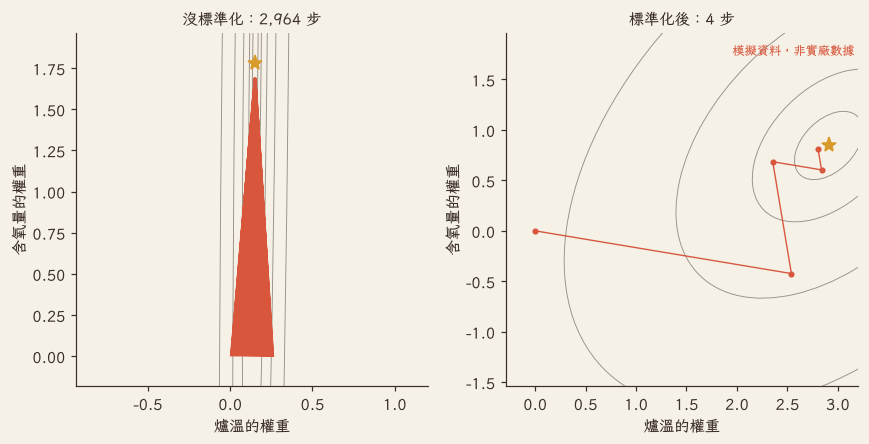

沒標準化：條件數 1,997，2,964 步；標準化後：條件數 2.5，4 步
爐溫和含氧量的相關係數 -0.44：兩者有相關，所以標準化後的碗「圓多了」，但不是正圓
沒標準化的前 6 步（爐溫權重來回跳）：[0.    0.266 0.    0.266 0.001 0.266 0.001]


In [5]:
for name, unit, s in zip(NAMES, UNITS, X[tr].T):
    print(f"{name:6s} 平均 {s.mean():>10,.1f} {unit:6s} 標準差 {s.std():>8,.2f}")

def gd_path(A, yv, cap=200_000, tol=0.01):
    # 全批次梯度下降法；回傳路徑、步數、條件數
    n = len(yv); G = A.T @ A / n; g = A.T @ yv / n
    lam = np.linalg.eigvalsh(2 * G); lr = 2 / (lam.max() + lam.min())
    w_opt = np.linalg.solve(G, g)
    loss = lambda w: ((A @ w - yv) ** 2).mean()
    L_opt = loss(w_opt); w = np.zeros(A.shape[1]); path = [w.copy()]
    while loss(w) - L_opt > tol * L_opt and len(path) <= cap:
        w = w - lr * 2 * (G @ w - g); path.append(w.copy())
    return dict(path=np.array(path), steps=len(path) - 1, cond=float(lam.max() / lam.min()),
                lr=float(lr), w_opt=w_opt, G=G, L_opt=float(L_opt))

PAIR = [2, 3]                                   # 爐溫、含氧量
yc = y[tr] - y[tr].mean()
A2_raw = X[tr][:, PAIR] - X[tr][:, PAIR].mean(0)
A2_std = A2_raw / A2_raw.std(0)
gd_raw = gd_path(A2_raw, yc)
gd_std = gd_path(A2_std, yc)
assert gd_raw["steps"] > 100 * gd_std["steps"]

def contour_ellipses(ax, res, levels):
    lam, vec = np.linalg.eigh(res["G"])
    ang = np.degrees(np.arctan2(vec[1, 1], vec[0, 1]))
    for c in levels:                            # L - L_opt = c × L_opt
        a, b = np.sqrt(c * res["L_opt"] / lam[1]), np.sqrt(c * res["L_opt"] / lam[0])
        ax.add_patch(Ellipse(res["w_opt"], 2 * a, 2 * b, angle=ang, fill=False, color=INK, lw=0.6, alpha=0.5))

LEVELS = [0.05, 0.25, 1, 3, 8]
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
for ax, res, title in [(axs[0], gd_raw, "沒標準化"), (axs[1], gd_std, "標準化後")]:
    contour_ellipses(ax, res, LEVELS)
    p = res["path"]; ax.plot(p[:, 0], p[:, 1], color=RED, lw=0.4 if len(p) > 50 else 0.9, marker="." if len(p) < 50 else None)
    ax.plot(*res["w_opt"], "*", color=AMBER, ms=10)
    pts = np.vstack([p, res["w_opt"]]); lo, hi = pts.min(0), pts.max(0); c = (lo + hi) / 2; half = 0.6 * max(hi - lo) + 1e-9
    ax.set_xlim(c[0] - half, c[0] + half); ax.set_ylim(c[1] - half, c[1] + half); ax.set_aspect("equal")
    ax.set_xlabel("爐溫的權重"); ax.set_ylabel("含氧量的權重")
    ax.set_title(f"{title}：{res['steps']:,} 步", fontsize=10)
tag(axs[1]); plt.tight_layout(); plt.show()
print(f"沒標準化：條件數 {gd_raw['cond']:,.0f}，{gd_raw['steps']:,} 步；標準化後：條件數 {gd_std['cond']:.1f}，{gd_std['steps']} 步")
print(f"爐溫和含氧量的相關係數 {np.corrcoef(A2_raw.T)[0, 1]:.2f}：兩者有相關，所以標準化後的碗「圓多了」，但不是正圓")
print(f"沒標準化的前 6 步（爐溫權重來回跳）：{np.round(gd_raw['path'][:7, 0], 3)}")

## 5. 特徵標準化
$z = \dfrac{x - \mu}{\sigma}$：減掉平均值，再除以標準差。**平均值和標準差只用訓練資料算**，測試資料（和以後上線的新資料）用同一組 $\mu, \sigma$。

接著用 4 個感測器全部一起比：
- 標準化後，梯度下降法要幾步？
- 沒標準化，走 100 萬步之後還差多少？梯度下降法每一步都是同一個線性變換 $w_{k+1}-w^* = M(w_k-w^*)$，所以第 $k$ 步可以用矩陣次方直接算，不必真的跑 100 萬次迴圈（下面先用 1 萬步驗證兩種算法一樣）。

用公式直接解：標準化前後的預測完全一樣 ✔
4 個感測器、標準化後：38 步走到離最低點 1% 以內（條件數 30）
4 個感測器、沒標準化：條件數 1.6e+13，走了 1,000,000 步，損失還是最低點的 764 倍


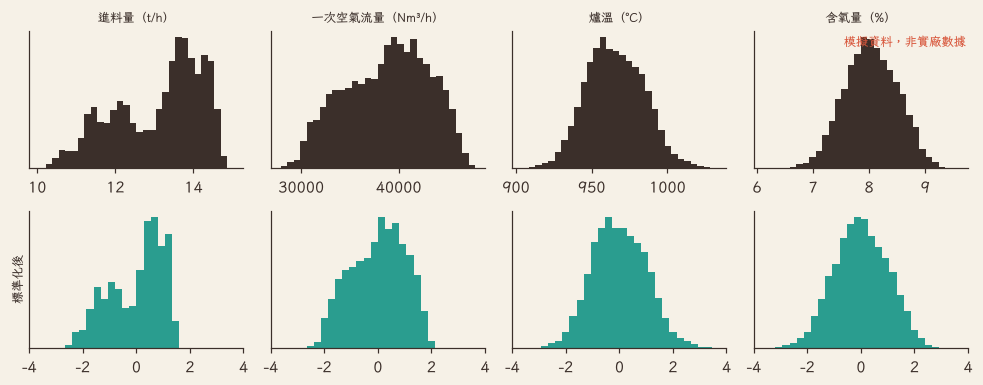

In [6]:
mu, sd = X[tr].mean(0), X[tr].std(0)
Z = (X - mu) / sd
assert np.allclose(Z[tr].mean(0), 0, atol=1e-9) and np.allclose(Z[tr].std(0), 1)

coef_std, *_ = np.linalg.lstsq(with_bias(Z[tr]), y[tr], rcond=None)
pred_std = with_bias(Z) @ coef_std
assert np.allclose(pred_std, pred_raw, atol=1e-6)   # 用公式解：標準化前後預測完全一樣
print("用公式直接解：標準化前後的預測完全一樣 ✔")

full_std = gd_path(with_bias(Z[tr]), y[tr])
print(f"4 個感測器、標準化後：{full_std['steps']} 步走到離最低點 1% 以內（條件數 {full_std['cond']:.0f}）")

A4 = with_bias(X[tr]); n = len(tr)
G4 = A4.T @ A4 / n; g4 = A4.T @ y[tr] / n
lam4 = np.linalg.eigvalsh(2 * G4); lr4 = 2 / (lam4.max() + lam4.min())
w4_opt = np.linalg.solve(G4, g4)
L4_opt = float(((A4 @ w4_opt - y[tr]) ** 2).mean())
M = np.eye(5) - lr4 * 2 * G4

def ratio_after(k):
    e = np.linalg.matrix_power(M, k) @ (np.zeros(5) - w4_opt)
    return float(1 + e @ G4 @ e / L4_opt)

w = np.zeros(5)
for _ in range(10_000):
    w = w - lr4 * 2 * (G4 @ w - g4)
assert np.isclose(((A4 @ w - y[tr]) ** 2).mean() / L4_opt, ratio_after(10_000), rtol=1e-6)
RAW_STEPS = 1_000_000
raw_ratio = ratio_after(RAW_STEPS)
print(f"4 個感測器、沒標準化：條件數 {lam4.max() / lam4.min():.1e}，走了 {RAW_STEPS:,} 步，損失還是最低點的 {raw_ratio:,.0f} 倍")

fig, axs = plt.subplots(2, 4, figsize=(9, 3.6))
for j, (name, unit) in enumerate(zip(NAMES, UNITS)):
    axs[0, j].hist(X[tr][:, j], bins=30, color=INK); axs[0, j].set_title(f"{name}（{unit}）", fontsize=8)
    axs[1, j].hist(Z[tr][:, j], bins=30, range=(-4, 4), color=TEAL); axs[1, j].set_xlim(-4, 4)
    for ax in axs[:, j]: ax.set_yticks([])
axs[1, 0].set_ylabel("標準化後", fontsize=8); tag(axs[0, 3]); plt.tight_layout(); plt.show()

## 6. 標準化之後，權重能比較了
- 原始單位的權重：意思是「這個感測器多 1 個單位」，單位不同就沒辦法比。
- 標準化後的權重：意思是「這個感測器多 1 個標準差」，大家用同一把尺。
- **注意**：進料量和一次空氣流量一起漲跌（相關係數見下），個別權重可能不穩定（換一批資料，大小甚至正負號都可能變）。模型可能更倚重空氣量，因為在這份模擬裡空氣設定值比實際進料**更早**反映操作員的調整；這不代表空氣會「產生」蒸汽（模擬裡空氣多反而讓蒸汽略少）。權重大 ≠ 原因。

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


進料量 vs 一次空氣流量 相關係數：0.84


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


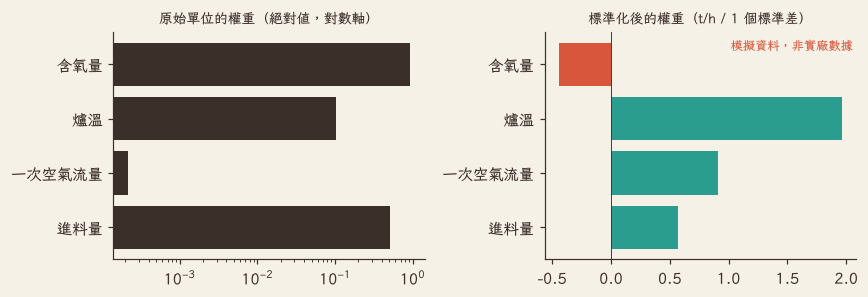

進料量    原始     0.510973   標準化   0.569
一次空氣流量 原始  0.000214078   標準化   0.912
爐溫     原始     0.102919   標準化   1.963
含氧量    原始    -0.935525   標準化  -0.444
原始權重大小相差 4,370 倍


In [7]:
corr = np.corrcoef(X[tr].T)
print(f"進料量 vs 一次空氣流量 相關係數：{corr[0, 1]:.2f}")
fig, axs = plt.subplots(1, 2, figsize=(8, 2.8))
axs[0].barh(NAMES, np.abs(coef_raw[1:]), color=INK); axs[0].set_xscale("log"); axs[0].set_title("原始單位的權重（絕對值，對數軸）", fontsize=9)
axs[1].barh(NAMES, coef_std[1:], color=[TEAL if v > 0 else RED for v in coef_std[1:]]); axs[1].axvline(0, color=INK, lw=0.6)
axs[1].set_title("標準化後的權重（t/h / 1 個標準差）", fontsize=9)
tag(axs[1]); plt.tight_layout(); plt.show()
for name, wr, ws in zip(NAMES, coef_raw[1:], coef_std[1:]):
    print(f"{name:6s} 原始 {wr:>12.6g}   標準化 {ws:>7.3f}")
print(f"原始權重大小相差 {np.abs(coef_raw[1:]).max() / np.abs(coef_raw[1:]).min():,.0f} 倍")

## 7. 拿沒看過的日子來測
後 4 天模型沒看過。每 10 分鐘畫一點：模擬目標值（接下來一小時的平均蒸汽流量）和模型預測值。
模擬資料比真實工廠乾淨，真實情況通常更難；模型在訓練資料和新資料上的差別，是下一集（EP04）的主題。

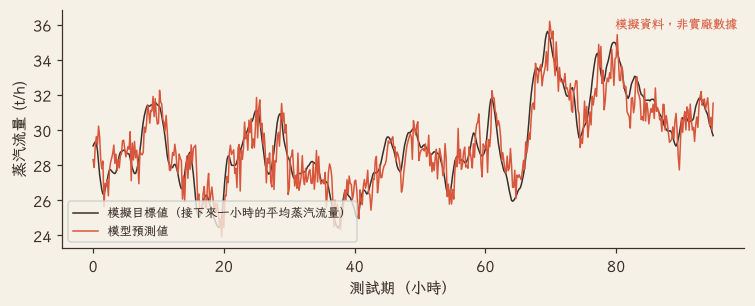

測試：平均絕對誤差 0.80 公噸／小時（平均蒸汽流量約 29 公噸／小時），R² = 0.83（訓練 R² = 0.85）


In [8]:
sel = te[::10]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot((sel - n_split) / 60, y[sel], color=INK, lw=1, label="模擬目標值（接下來一小時的平均蒸汽流量）")
ax.plot((sel - n_split) / 60, pred_raw[sel], color=RED, lw=1, label="模型預測值")
ax.set_xlabel("測試期（小時）"); ax.set_ylabel("蒸汽流量 (t/h)"); ax.legend(fontsize=8, loc="lower left"); tag(ax); plt.show()
MAE_TEST, R2_TEST, R2_TRAIN = mae(y[te], pred_raw[te]), r2(y[te], pred_raw[te]), r2(y[tr], pred_raw[tr])
assert 0.6 < R2_TEST < 0.95
print(f"測試：平均絕對誤差 {MAE_TEST:.2f} 公噸／小時（平均蒸汽流量約 {y[te].mean():.0f} 公噸／小時），R² = {R2_TEST:.2f}（訓練 R² = {R2_TRAIN:.2f}）")

## 8. 匯出資料給影片使用
影片（Remotion）讀這個 JSON 來畫圖，所以影片裡的圖和數字跟這本 notebook 完全一樣。

In [9]:
def rn(v, d=4): return [round(float(x), d) for x in np.ravel(v)]

def ellipse_spec(res):
    lam, vec = np.linalg.eigh(res["G"])
    return {"w_opt": rn(res["w_opt"], 5), "L_opt": res["L_opt"], "lam": rn(lam, 8),
            "vec": [rn(vec[:, 0], 6), rn(vec[:, 1], 6)], "levels": LEVELS,
            "steps": res["steps"], "cond": res["cond"], "lr": res["lr"],
            "path": [rn(p, 5) for p in res["path"]]}

ov = np.arange(0, 2 * 1440, 5)                   # 前 2 天，每 5 分鐘
demo_now = 26 * 60                               # 第 4 段「現在」的位置（第 2 天 02:00）
hist = {}
for j, name in enumerate(NAMES):
    c_raw, e_raw = np.histogram(X[tr][:, j], bins=30)
    c_std, e_std = np.histogram(Z[tr][:, j], bins=32, range=(-4, 4))
    hist[name] = {"raw_edges": rn(e_raw, 3), "raw_counts": [int(c) for c in c_raw],
                  "std_edges": rn(e_std, 3), "std_counts": [int(c) for c in c_std]}

out = {
    "meta": {"seed": 2026, "days": DAYS, "train_days": TRAIN_DAYS, "test_days": TEST_DAYS, "horizon_min": H,
             "simulated": True, "label": LABEL},
    "sensors": {"names": NAMES, "units": UNITS,
                "mean": rn(X[tr].mean(0), 3), "sd": rn(X[tr].std(0), 3),
                "min": rn(X[tr].min(0), 3), "max": rn(X[tr].max(0), 3)},
    "overview": {"t_h": rn(ov / 60, 3), "feed": rn(feed[ov], 2), "air": rn(air[ov], 0), "temp": rn(temp[ov], 1),
                 "o2": rn(o2[ov], 2), "steam": rn(steam[ov], 2)},
    "target_demo": {"t_min": [int(v) for v in range(demo_now - 120, demo_now + 121)],
                    "steam": rn(steam[demo_now - 120:demo_now + 121], 2), "now": demo_now, "y_now": round(float(y[demo_now]), 2)},
    "table": [{"day": int(r // 1440 + 1), "hhmm": f"{(r % 1440) // 60:02d}:{r % 60:02d}",
               "x": [round(float(X[r, 0]), 1), int(round(X[r, 1], -1)), int(round(X[r, 2])), round(float(X[r, 3]), 1)],
               "y": round(float(y[r]), 1)} for r in table_rows],
    "fit": {"b_raw": float(coef_raw[0]), "w_raw": rn(coef_raw[1:], 8), "b_std": float(coef_std[0]), "w_std": rn(coef_std[1:], 4),
            "mu": rn(mu, 4), "sd": rn(sd, 4), "mae_test": MAE_TEST, "r2_test": R2_TEST, "r2_train": R2_TRAIN,
            "raw_weight_ratio": float(np.abs(coef_raw[1:]).max() / np.abs(coef_raw[1:]).min()),
            "corr_feed_air": float(corr[0, 1]), "same_prediction": True},
    "gd2d": {"features": [NAMES[j] for j in PAIR], "raw": ellipse_spec(gd_raw), "std": ellipse_spec(gd_std)},
    "gd_full": {"std_steps": full_std["steps"], "std_cond": full_std["cond"],
                "raw_steps": RAW_STEPS, "raw_loss_ratio": raw_ratio, "raw_cond": float(lam4.max() / lam4.min())},
    "hist": hist,
    "test": {"t_h": rn((sel - n_split) / 60, 3), "y": rn(y[sel], 2), "pred": rn(pred_raw[sel], 2)},
}
Path("data").mkdir(exist_ok=True)
Path("data/v04.json").write_text(json.dumps(out, ensure_ascii=False), encoding="utf-8")
print(f"已匯出 data/v04.json（{Path('data/v04.json').stat().st_size / 1024:.0f} KB）")

已匯出 data/v04.json（102 KB）
